Código adaptado de:

[1] A. Géron, Hands-On Machine Learning with Scikit-Learning, Keras & Tensorflow, Third Edition, O'Reilly, 2022.

# Laboratório 9: Modelos de Difusão (dados 2D)

## Importações

In [ ]:
!pip install torchinfo                                                          # Sumário de modelos (camadas e shapes)

In [ ]:
from __future__ import annotations                                              # Anotações de tipo adiadas
import os                                                                       # Arquivos locais
import time                                                                     # Duração do treinamento e da geração
from typing import NamedTuple                                                   # Histórico de treinamento
import gdown                                                                    # Download do Google Drive
from tqdm.auto import tqdm                                                      # Barra de progresso
import numpy as np                                                              # Operações numéricas
from matplotlib import pyplot as plt                                            # Gráficos
import pandas as pd                                                             # Tabelas de resultados
import torch                                                                    # PyTorch
import torch.nn as nn                                                           # Camadas de redes neurais
import torch.nn.functional as F                                                 # Funções de perda
import torch.optim as optim                                                     # Otimizadores (Adam)
from torch.utils.data import DataLoader, TensorDataset                          # Mini-lotes a partir de tensores
from torchinfo import summary                                                   # Sumário de modelos
from sklearn import datasets                                                    # Conjuntos de dados 2D
from sklearn.preprocessing import StandardScaler                                # Padronização das coordenadas

In [ ]:
plt.rcParams.update({
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
})

## Funções auxiliares para visualização

In [ ]:
UTILS_URL = ("https://drive.google.com/file/d/18LM-TaKPs9XGTUgWMXMzk7ESNiiJMz6K/view?usp=sharing")
if not os.path.exists("diffusion_utils.py"):                                    # Baixa só se ainda não existir
    try:
        gdown.download(UTILS_URL, "diffusion_utils.py", quiet=True, fuzzy=True)
    except Exception as error:
        print(f"Falha no download de diffusion_utils.py: {error}")

from diffusion_utils import (                                                   # Funções auxiliares
    _frame, animate_reverse_process, compare_processes, compare_training_curves,
    load_datasaurus, plot_activation, plot_data, plot_datasaurus,
    plot_noise_schedule, plot_time_encoding, plot_training_curve,
    plot_trajectories, show_animation, show_figure,
)

## Hiperparâmetros

| Hiperparâmetro | Descrição |
|---|---|
| `DEVICE` | dispositivo de execução: GPU, se houver, ou CPU |
| `SEED` | semente dos dados, dos modelos e das amostras |
| `BATCH_SIZE` | tamanho do mini-lote de treinamento |
| `NUM_STEPS` | número de passos de difusão $T$ |
| `MODE` | cronograma de ruído: `"linear"`, `"quad"` ou `"cosine"` |
| `DATASET` | conjunto de dados 2D: `"moon"`, `"circle"`, `"scurve"` ou `"swiss_roll"` |
| `NUM_SAMPLES` | número de pontos do conjunto de treinamento |
| `NUM_EPOCHS` | número de épocas de treinamento |
| `LEARNING_RATE` | taxa de aprendizado do Adam |
| `EMBEDDING_SIZE` | dimensão $D$ da codificação temporal |
| `BATCH_SIZE_SAMPLING` | número de pontos gerados pelo processo reverso |

In [ ]:
DEVICE = (torch.accelerator.current_accelerator().type                          # GPU, se houver; senão, CPU
          if torch.accelerator.is_available() else "cpu")
SEED = 42                                                                       # Semente dos dados, modelos e amostras
BATCH_SIZE = 256                                                                # Tamanho do mini-lote
NUM_STEPS = 1_000                                                               # Número de passos de difusão T
MODE = "cosine"                                                                 # "linear", "quad" ou "cosine"
DATASET = "swiss_roll"                                                          # "moon", "circle", "scurve" ou "swiss_roll"
NUM_SAMPLES = 100_000                                                           # Pontos de treinamento
NUM_EPOCHS = 50                                                                 # Épocas de treinamento
LEARNING_RATE = 1e-3                                                            # Taxa de aprendizado do Adam
EMBEDDING_SIZE = 32                                                             # Dimensão D da codificação temporal
BATCH_SIZE_SAMPLING = 1024                                                      # Pontos gerados na amostragem

In [ ]:
print(f"Usando {DEVICE}.")

Usando cpu.


## Dados

Os dados são pontos do plano sobre uma curva. O modelo aprende a gerar novos pontos com a mesma distribuição, partindo de ruído Gaussiano.

- **Dados:** $\mathbf{x}_0 \in \mathbb{R}^2$(*moons*, *circles*, *S curve* ou *swiss roll*);
- **Padronização:** cada coordenada tem média $0$ e variância $1$, a escala de $\mathcal{N}(\mathbf{0}, \mathbf{I})$;
- **Distribuição a priori:** $\mathcal{N}(\mathbf{0}, \mathbf{I})$, onde o processo direto termina e o processo reverso começa;
- **Treinamento:** `NUM_SAMPLES` pontos, em mini-lotes embaralhados (`train_dl`).

In [ ]:
def load_datasets_2d(num_samples, dataset):
    """Gera pontos 2D do conjunto escolhido, com as coordenadas padronizadas."""
    kwargs = dict(n_samples=num_samples, noise=0.0, random_state=SEED)          # Argumentos comuns
    match dataset:
        case "moon":
            X = datasets.make_moons(**kwargs)[0]                                # Duas meias-luas
        case "circle":
            X = datasets.make_circles(factor=0.5, **kwargs)[0]                  # Dois círculos concêntricos
        case "scurve":
            X = datasets.make_s_curve(**kwargs)[0][:, [0, 2]]                   # Curva em S, plano (x, z)
        case "swiss_roll":
            X = datasets.make_swiss_roll(hole=True, **kwargs)[0]                # Rocambole 3D
            X = X[:, [0, 2]]                                                    # Plano da espiral
        case _:
            raise ValueError(f"Conjunto desconhecido: {dataset}")
    X = StandardScaler().fit_transform(X)                                       # Média 0, variância 1
    return torch.tensor(X, dtype=torch.float32)                                 # Tensor (num_samples, 2)

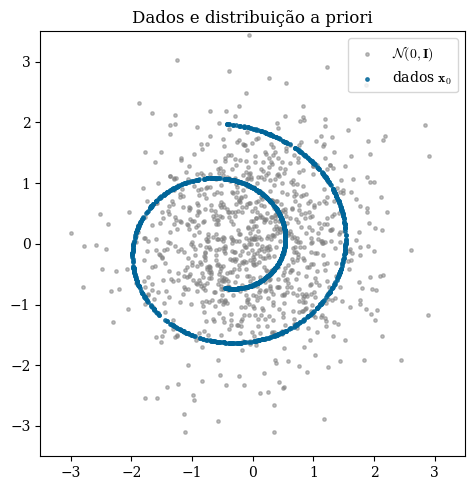

In [ ]:
X = load_datasets_2d(num_samples=NUM_SAMPLES, dataset=DATASET)                  # x_0, shape (NUM_SAMPLES, 2)
train_ds = TensorDataset(X)                                                     # Conjunto de tensores
train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)            # Mini-lotes embaralhados
plot_data(X)                                                                    # Dados sobre amostras de N(0, I)

## Modelo de difusão

Um modelo de difusão [*diffusion model*] aprende a gerar dados invertendo um processo que os destrói aos poucos:

- **processo direto** [*forward process*] $q$: fixo; adiciona ruído Gaussiano em $T$ passos e leva um dado $\mathbf{x}_0$ a $\mathbf{x}_T$, com distribuição aproximadamente $\mathcal{N}(\mathbf{0}, \mathbf{I})$;
- **processo reverso** [*reverse process*] $p_\theta$: aprendido por uma rede neural de parâmetros $\theta$; remove o ruído passo a passo, de $\mathbf{x}_T \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$ até uma amostra $\mathbf{x}_0$.

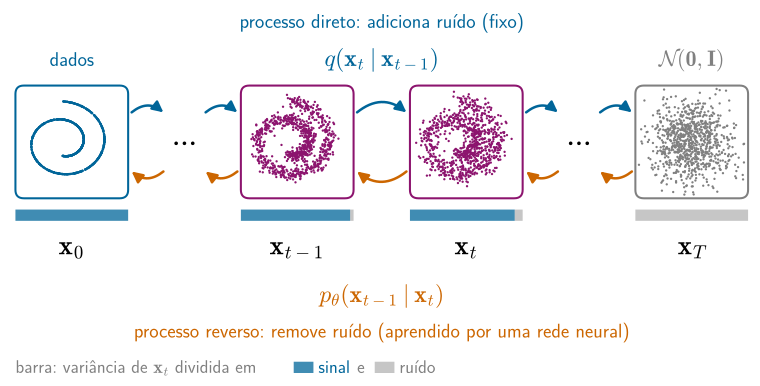

In [ ]:
show_figure("processos_difusao")                                                # Processos direto e reverso

O modelo implementado é o DDPM [*denoising diffusion probabilistic model*], dividido em cinco partes:

| Parte | Descrição |
|---|---|
| `NoiseScheduler` | cronograma de ruído e kernel de difusão |
| `TimeEncoding` | codificação do passo $t$ |
| `NeuralNet` | rede que prediz o ruído |
| `DiffusionModel` | perda de treinamento, passo reverso e geração |
| `train_diffusion_model` | laço de treinamento |

### Processo direto

Cada passo multiplica a saída do passo anterior por $\sqrt{1 - \beta_t}$ e soma ruído multiplicado por $\sqrt{\beta_t}$:
<br>
<br>
$$
\mathbf{x}_t = \sqrt{1-\beta_t}\,\mathbf{x}_{t-1} + \sqrt{\beta_t}\,\mathbf{\epsilon}_t,
\iff
q(\mathbf{x}_t \mid \mathbf{x}_{t-1}) = \mathcal{N}\left(\mathbf{x}_t ; \sqrt{1 - \beta_t}\,\mathbf{x}_{t-1},\ \beta_t \mathbf{I}\right)
, \qquad t = 1, \ldots, T.$$
<br>

#### Kernel de difusão

Compondo os passos, $\mathbf{x}_t$ pode ser amostrado diretamente a partir de $\mathbf{x}_0$ sem percorrer a cadeia através do **kernel de difusão**:
<br>
<br>
$$\boxed{\quad \mathbf{x}_t = \underbrace{\sqrt{\bar{\alpha}_t}}_{\substack{\text{fator de escala}\\\text{do sinal}}}\,
\cdot
\underbrace{\mathbf{x}_0 }_{\substack{\text{sinal}\\\text{(ex.: imagem)}}}
+ \underbrace{\sqrt{1 - \bar{\alpha}_t}}_{\substack{\text{fator de escala}\\\text{do ruído}}}\,
\cdot
\underbrace{\boldsymbol{\epsilon}}_{\text{ruído}}
\iff
q(\mathbf{x}_t \mid \mathbf{x}_0) = \mathcal{N}\left(\mathbf{x}_t ; \sqrt{\bar{\alpha}_t}\,\mathbf{x}_0,\ (1 - \bar{\alpha}_t)\mathbf{I}\right) \quad}$$
<br>
- $\alpha_t = 1 - \beta_t$, para $t = 1, \ldots, T$;
- $\bar{\alpha}_t = \prod\limits_{s=1}^{t} \alpha_s$, com $\bar{\alpha}_0 = 1$ (convenção $\alpha_0 = 1$ e $\beta_0 = 0$: $\mathbf{x}_0$ não tem ruído);
- $\boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$.

Como $\bar{\alpha}_t$ decresce de $1$ a quase $0$, o sinal some e $\mathbf{x}_T$ fica próximo de $\mathcal{N}(\mathbf{0}, \mathbf{I})$.

A figura mostra o mesmo ponto $\mathbf{x}_0$ em três passos $t$ crescentes:

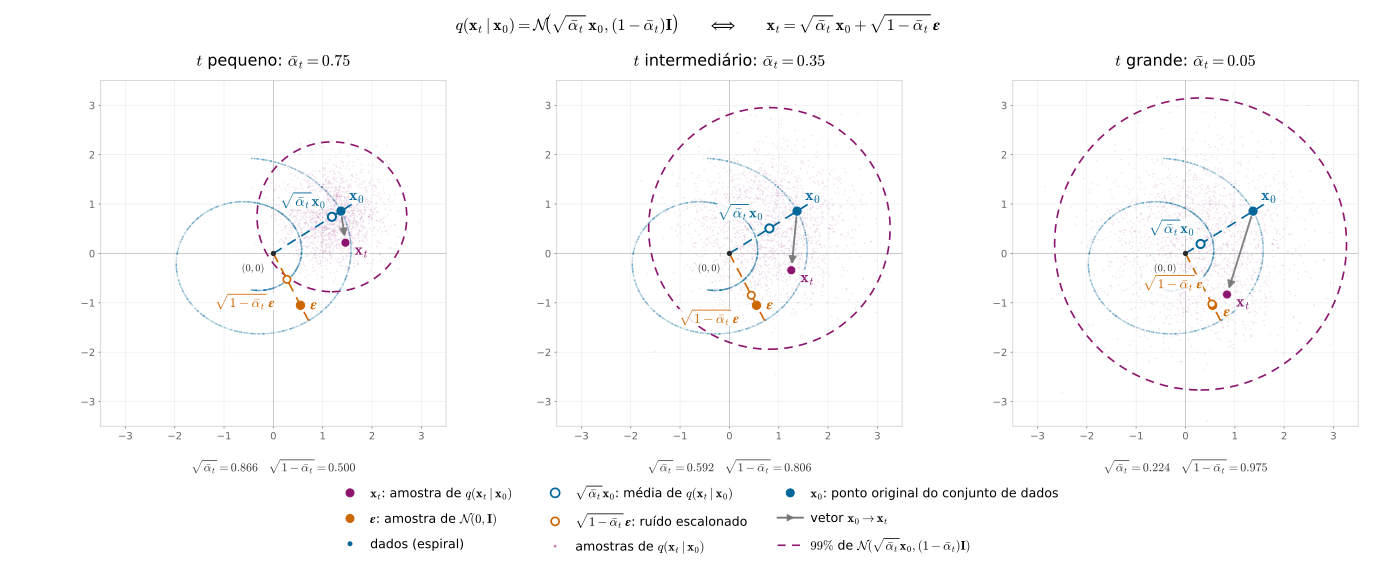

In [ ]:
show_figure("kernel_difusao")                                                   # Kernel de difusão

A animação a seguir mostra como a distribuição condicional $q(\mathbf{x}_t \mid \mathbf{x}_0)$ se transforma à medida que $t$ aumenta de $0$ a $T$. O ponto original $\mathbf{x}_0$ permanece fixo, enquanto o cronograma de ruído determina a contribuição do sinal e do ruído em cada passo.

- **Sinal:** a média $\sqrt{\bar{\alpha}_t}\mathbf{x}_0$ (círculo azul vazio) aproxima-se da origem à medida que $\bar{\alpha}_t$ diminui.
- **Ruído:** o termo $\sqrt{1-\bar{\alpha}_t}\boldsymbol{\epsilon}$ (círculo laranja vazio) aumenta sua contribuição para a posição de $\mathbf{x}_t$ (ponto roxo).
- **Distribuição condicional:** os pontos roxos representam amostras de $q(\mathbf{x}_t \mid \mathbf{x}_0)$. O círculo roxo tracejado delimita uma região na qual uma amostra de $q(\mathbf{x}_t \mid \mathbf{x}_0)$ tem 99% de probabilidade de se encontrar.

Observe que quando $\bar{\alpha}_t \to 0$, temos $q(\mathbf{x}_t \mid \mathbf{x}_0) \approx \mathcal{N}(\mathbf{0},\mathbf{I})$.

**Observação:** a animação utiliza o mesmo $\mathbf{x}_0$ e as mesmas realizações de ruído ao longo dos quadros, para facilitar a visualização. Ela **não** representa uma trajetória obtida pela simulação sequencial dos passos $q(\mathbf{x}_t\mid\mathbf{x}_{t-1})$.

In [ ]:
show_animation("kernel_difusao_animado.html")                                   # Animação de q(x_t | x_0)

Output hidden; open in https://colab.research.google.com to view.

#### Cronograma de ruído $\{\beta_t\}_{t=1}^T$

**Lembrete:** função cosseno

In [ ]:
T = NUM_STEPS                                                                   # Número total de passos T
t = np.arange(T + 1)                                                            # Passos 0, 1, ..., T
f = np.cos((t / T) * np.pi / 2)                                                 # De cos(0) = 1 a cos(π/2) = 0

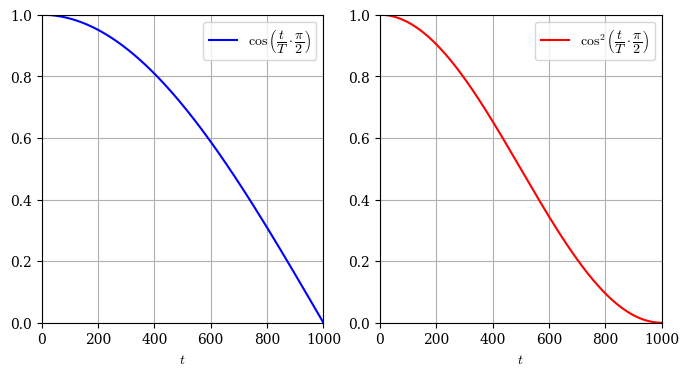

In [ ]:
plt.figure(figsize=(8, 4))                                                      # Figura com 2 subplots

plt.subplot(1, 2, 1)                                                            # cos((t/T)·π/2)
plt.plot(t, f, "b",                                                             # Curva do cosseno
         label=r"$\cos\left(\dfrac{t}{T}\cdot\dfrac{\pi}{2}\right)$")
plt.axis([0, T, 0, 1])                                                          # t em [0, T], valor em [0, 1]
plt.grid(True)                                                                  # Grade
plt.xlabel(r"$t$")                                                              # Passo de tempo
plt.legend()                                                                    # Legenda

plt.subplot(1, 2, 2)                                                            # cos²((t/T)·π/2)
plt.plot(t, f**2, "r",                                                          # Curva do cosseno ao quadrado
         label=r"$\cos^2\left(\dfrac{t}{T}\cdot\dfrac{\pi}{2}\right)$")
plt.axis([0, T, 0, 1])                                                          # t em [0, T], valor em [0, 1]
plt.grid(True)                                                                  # Grade
plt.xlabel(r"$t$")                                                              # Passo de tempo
plt.legend()                                                                    # Legenda

plt.show()                                                                      # Exibe a figura

O cronograma de ruído [*noise schedule*] define $\beta_t$ em cada passo. O cronograma cosseno define $\bar{\alpha}_t$ e obtém $\beta_t$ a partir dele.


$\quad \displaystyle  \bar{\alpha}_t = \prod_{s=1}^{t} \alpha_s  = \alpha_t \cdot \underbrace{\prod_{s=1}^{t-1} \alpha_s}_{\bar{\alpha}_{t-1}} = \alpha_t \cdot \bar{\alpha}_{t-1}
\implies \underbrace{\alpha_t}_{(1-\beta_t)} = \frac{\bar{\alpha}_t}{\bar{\alpha}_{t-1}}
\implies 1-\beta_t = \frac{\bar{\alpha}_t}{\bar{\alpha}_{t-1}}
\implies \boxed{\beta_t = 1 - \frac{\bar{\alpha}_t}{\bar{\alpha}_{t-1}}}$


Dessa forma:

$$\beta_t = 1 - \frac{\bar{\alpha}_t}{\bar{\alpha}_{t-1}},
\qquad
\bar{\alpha}_t = \frac{f(t)}{f(0)},
\qquad
f(t) = \cos^2\left(\frac{t/T + s}{1 + s} \cdot \frac{\pi}{2}\right),
\qquad
\displaystyle \alpha_t = \dfrac{\bar{\alpha}_t}{\bar{\alpha}_{t-1}} = \frac{f(t)/f(0)}{f(t-1)/f(0)} = \frac{f(t)}{f(t-1)}, \qquad t=1,\dots,T.$$

- $s$ é um deslocamento pequeno ($s = 0.008$) que evita $\beta_t$ quase nulo perto de $t = 0$;
- $\beta_t$ é limitado a $0.999$, para evitar instabilidade perto de $t = T$, onde $f(t) \to 0$;
- $\bar{\alpha}_t$ depende de $t$ só pela fração $t/T$ da cadeia.

`NoiseScheduler` também implementa os cronogramas linear (`"linear"`: $\beta_t$ cresce linearmente de $10^{-4}$ a $0.02$) e quadrático (`"quad"`: $\sqrt{\beta_t}$ cresce linearmente), e o kernel de difusão, em `forward_diffusion`.

| Atributo | Nomenclatura | Significado............................................. |
|---|---|---|
| `T` | $T$ | número de passos de difusão |
| `betas` | $\beta_t$ | variância do ruído adicionado no passo $t$ |
| `alphas` | $\alpha_t$ | fração do sinal mantida no passo $t$ |
| `alphas_bar` | $\bar{\alpha}_t$ | nível do sinal em $\mathbf{x}_t$ |

Cada vetor tem $T + 1$ posições, para que o índice coincida com $t$.

In [ ]:
class NoiseScheduler(nn.Module):
    """Cronograma de ruído (betas, alphas, alphas_bar) e kernel de difusão."""

    def __init__(self, T, mode="linear"):
        super().__init__()
        self.T = int(T)                                                         # Número de passos T
        self.mode = mode                                                        # "linear", "quad" ou "cosine"
        match mode:
            case "linear":
                betas = self._make_linear()                                     # β_t cresce linearmente
            case "quad":
                betas = self._make_quad()                                       # √β_t cresce linearmente
            case "cosine":
                betas = self._make_cosine()                                     # β_t obtido de ᾱ_t
            case _:
                raise NotImplementedError(f"Cronograma desconhecido: {mode}")
        alphas = 1.0 - betas                                                    # α_t = 1 - β_t, com α_0 = 1
        alphas_bar = torch.cumprod(alphas, dim=0)                               # ᾱ_t = ∏ α_s, com ᾱ_0 = 1
        self.register_buffer("betas", betas.float())                            # (T+1,), acompanha o dispositivo
        self.register_buffer("alphas", alphas.float())                          # (T+1,)
        self.register_buffer("alphas_bar", alphas_bar.float())                  # (T+1,)

    def _make_linear(self, beta_1=1e-4, beta_T=2e-2):
        """beta_t de beta_1 a beta_T em progressão linear, com beta_0 = 0."""
        betas = torch.linspace(beta_1, beta_T, self.T, dtype=torch.float64)     # β_1, ..., β_T
        return torch.cat([torch.zeros(1, dtype=torch.float64), betas])          # Acrescenta β_0 = 0

    def _make_quad(self, beta_1=1e-4, beta_T=2e-2):
        """Raiz de beta_t de raiz(beta_1) a raiz(beta_T) em progressão linear."""
        roots = torch.linspace(beta_1**0.5, beta_T**0.5, self.T,                # √β_1, ..., √β_T
                               dtype=torch.float64)
        return torch.cat([torch.zeros(1, dtype=torch.float64), roots**2])       # β_0 = 0 e β_t

    def _make_cosine(self, s=0.008, max_beta=0.999):
        """beta_t = 1 - f(t)/f(t-1), com f(t) = cos^2(((t/T + s)/(1 + s)) pi/2)."""
        t = torch.arange(self.T + 1, dtype=torch.float64)                       # Passos 0, 1, ..., T
        f = torch.cos((t / self.T + s) / (1 + s) * torch.pi / 2) ** 2           # f(t), shape (T+1,)
        betas = (1 - f[1:] / f[:-1]).clamp(max=max_beta)                        # β_1, ..., β_T, limitados
        return torch.cat([torch.zeros(1, dtype=torch.float64), betas])          # Acrescenta β_0 = 0

    def forward_diffusion(self, x0, t, noise):
        """Amostra x_t ~ q(x_t | x_0) pelo kernel de difusão: (B, 2) -> (B, 2)."""
        alpha_bar = self.alphas_bar[t].view(-1, 1)                              # ᾱ_t, shape (B, 1)
        return alpha_bar.sqrt() * x0 + (1 - alpha_bar).sqrt() * noise           # √ᾱ_t·x_0 + √(1 - ᾱ_t)·ε

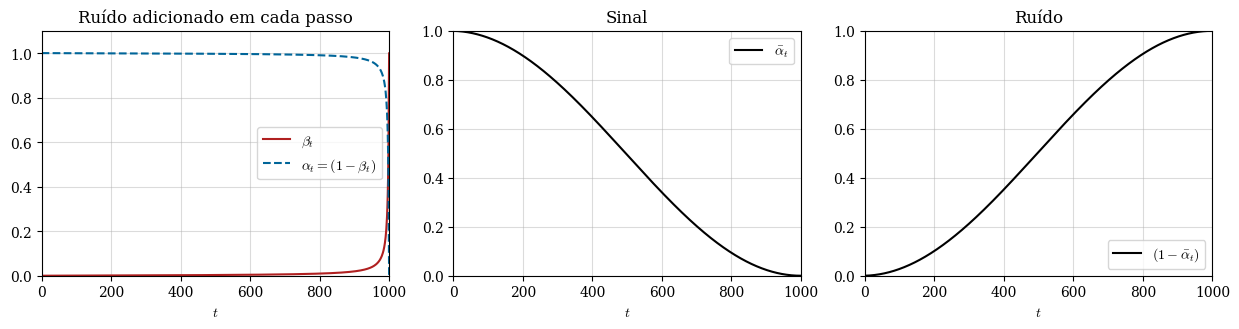

In [ ]:
noise_scheduler = NoiseScheduler(T=NUM_STEPS, mode="cosine").to(DEVICE)         # T = 1000, cosseno
plot_noise_schedule(noise_scheduler)                                            # β_t, α_t e ᾱ_t

Variáveis:
*   `alphas`: $[\alpha_0, \alpha_1, \ldots, \alpha_T]$.
*   `alphas_bar`: $[\bar{\alpha}_0, \bar{\alpha}_1, \ldots, \bar{\alpha}_T]$.
*   `betas`: $[\beta_0, \beta_1, \ldots, \beta_T]$.

In [ ]:
print(f'betas:')                                                                # Imprime β_t: ruído adicionado em cada passo
print(f'beta[0]={noise_scheduler.betas[0]: .4f}')
print(f'beta[T]={noise_scheduler.betas[-1]: .4f}')
print(f'shape={noise_scheduler.betas.shape}')
print(f'valores={noise_scheduler.betas}\n')

print(f'alphas:')                                                               # Imprime α_t = 1 - β_t: sinal mantido
print(f'alphas[0]={noise_scheduler.alphas[0]: .4f}')
print(f'alphas[T]={noise_scheduler.alphas[-1]: .4f}')
print(f'shape={noise_scheduler.alphas.shape}')
print(f'valores={noise_scheduler.alphas}\n')

print(f'alphas_bar:')                                                           # Imprime ᾱ_t = ∏ α_s: sinal acumulado até t
print(f'alphas_bar[0]={noise_scheduler.alphas_bar[0]: .4f}')
print(f'alphas_bar[T]={noise_scheduler.alphas_bar[-1]: .4f}')
print(f'shape={noise_scheduler.alphas_bar.shape}')
print(f'valores={noise_scheduler.alphas_bar}\n')

betas:
beta[0]= 0.0000
beta[T]= 0.9990
shape=torch.Size([1001])
valores=tensor([0.0000e+00, 4.1284e-05, 4.6142e-05,  ..., 5.5555e-01, 7.5000e-01,
        9.9900e-01])

alphas:
alphas[0]= 1.0000
alphas[T]= 0.0010
shape=torch.Size([1001])
valores=tensor([1.0000, 1.0000, 1.0000,  ..., 0.4444, 0.2500, 0.0010])

alphas_bar:
alphas_bar[0]= 1.0000
alphas_bar[T]= 0.0000
shape=torch.Size([1001])
valores=tensor([1.0000e+00, 9.9996e-01, 9.9991e-01,  ..., 9.7150e-06, 2.4288e-06,
        2.4288e-09])



O processo direto aplicado aos dados:

In [ ]:
BLUE = "#006599"

def plot_forward_process(noise_scheduler, data, num_frames=11, num_points=1000, seed=42, title=None, color=BLUE):
    """Quadros de q(x_t) de t = 0 a t = T."""
    T = noise_scheduler.T                                                       # Número de passos
    times = (np.unique(np.linspace(0, T, num_frames)                            # Passos exibidos: 0, ..., T
            .round()
            .astype(int)
            ))
    device = noise_scheduler.betas.device                                       # Dispositivo do cronograma
    x0 = data[:num_points].to(device)                                           # Pontos limpos x_0
    torch.manual_seed(seed)                                                     # Fixa o ruído
    noise = torch.randn_like(x0)                                                # Mesmo ε em todos os quadros
    fig, axs = plt.subplots(1, len(times),                                      # Um quadro por passo
                            figsize=(1.75 * len(times), 2.3))
    for ax, t in zip(np.atleast_1d(axs), times):
        t_batch = torch.full((len(x0),), int(t), dtype=torch.long,              # Mesmo t para todos os pontos
                             device=device)
        x_t = noise_scheduler.forward_diffusion(x0, t_batch, noise).cpu()       # x_t ~ q(x_t | x_0)
        label = rf"$q(\mathbf{{x}}_{{{t}}})$"                                   # Título do quadro
        _frame(ax, x_t, color, label)                                           # Quadro do passo t
    if title:
        fig.suptitle(title)                                                     # Identifica a execução
    plt.tight_layout()                                                          # Ajusta as margens
    plt.show()                                                                  # Exibe a figura

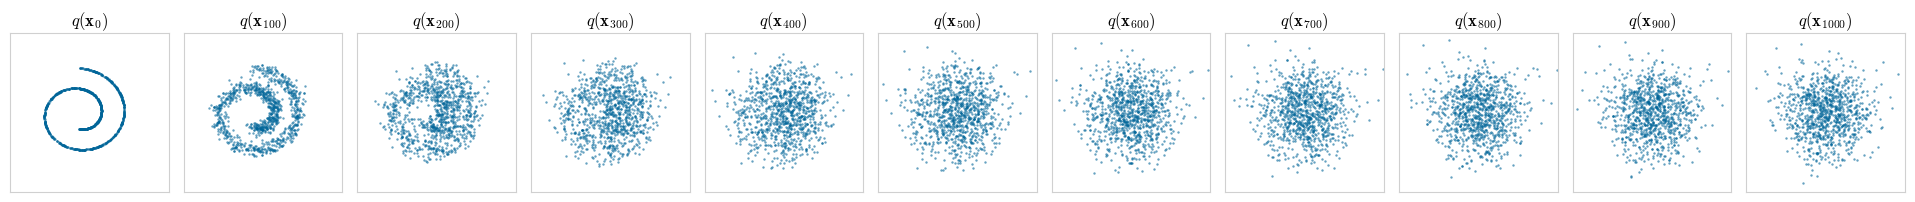

In [ ]:
plot_forward_process(noise_scheduler, X)                                        # q(x_t) em 11 passos

### Processo reverso

Para gerar dados, é preciso inverter o processo direto, mas $q(\mathbf{x}_{t-1} \mid \mathbf{x}_t)$ é **intratável**.

O processo reverso é modelado por
<br>
<br>
$$p_\theta(\mathbf{x}_{t-1} \mid \mathbf{x}_t) = \mathcal{N}\left(\mathbf{x}_{t-1} ; \boldsymbol{\mu}_\theta(\mathbf{x}_t, t),\ \sigma_t^2 \mathbf{I}\right), \qquad \sigma_t^2 = \beta_t,$$
<br>
com a média calculada a partir do ruído predito por uma rede neural, $\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)$.
<br>
<br>
$$\mathbf{x}_{t-1} = \underbrace{\frac{1}{\sqrt{\alpha_t}}\left(\mathbf{x}_t - \frac{\beta_t}{\sqrt{1 - \bar{\alpha}_t}}\,{\color{red}{\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)}}\right)}_{\text{média: } \boldsymbol{\mu}_\theta(\mathbf{x}_t, t)} + \underbrace{\sigma_t\,\mathbf{z}}_{\text{ruído novo}}, \qquad \mathbf{z} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$$
<br>
1. a rede prediz o ruído contido em $\mathbf{x}_t$, $\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)$;
2. a média $\boldsymbol{\mu}_\theta(\mathbf{x}_t, t)$ remove uma parte desse ruído e reescala o ponto;
3. soma-se ruído novo, $\sigma_t \mathbf{z}$, exceto no último passo ($t = 1$), em que $\mathbf{z} = \mathbf{0}$.

A rede recebe o ponto ruidoso $\mathbf{x}_t$ e o passo $t$. A rede neural prediz quanto ruído há em $\mathbf{x}_t$.

Um passo reverso, $\mathbf{x}_t \to \mathbf{x}_{t-1}$:

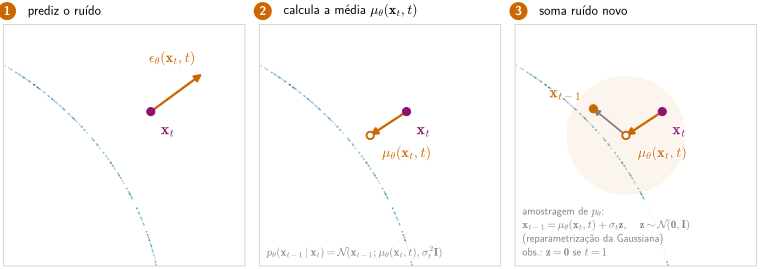

In [ ]:
show_figure("passo_reverso")                                                    # Um passo reverso

#### Codificação temporal

A rede não recebe o inteiro $t$, mas a **codificação temporal** [*time encoding*] senoidal $\mathbf{e}(t) \in \mathbb{R}^D$, com pares (seno, cosseno) de frequências decrescentes:

$$
\mathbf{e}(t) = \bigl[
\underbrace{\sin(\omega_0 t)}_{e_0(t)},\,
\underbrace{\cos(\omega_0 t)}_{e_1(t)},\,
\underbrace{\sin(\omega_1 t)}_{e_2(t)},\,
\underbrace{\cos(\omega_1 t)}_{e_3(t)},\,
\dots,\,
\underbrace{\sin(\omega_{\frac{D}{2} - 1} t)}_{e_{D-2}(t)},\,
\underbrace{\cos(\omega_{\frac{D}{2}  - 1} t)}_{e_{D-1}(t)}
\bigr]_{1 \times D}, \qquad \omega_i = \frac{1}{L^{2i/D}}, \qquad i = 0, 1, \ldots, \frac{D}{2} - 1,
$$

com $t \in \{0, 1, \ldots, T\}$, $D$ é o comprimento desejado do embedding temporal (número par) e $L = 100$ no código.

Cada par $(2i,2i+1)$ usa a mesma frequência e é dado por:

$
\begin{aligned}
\text{Para as dimensões pares:}  &\quad e_{2i}(t)   = \sin \left( \frac{t}{L^{2i/D}} \right), \\[0.5em]
\text{Para as dimensões ímpares:}&\quad e_{2i+1}(t) = \cos \left( \frac{t}{L^{2i/D}} \right).
\end{aligned}
$

O codificação senoidal completa é:

$
\mathbf{E} =
\begin{bmatrix}
e_0(0) & e_1(0) & \dots & e_{D-1}(0) \\
e_0(1) & e_1(1) & \dots & e_{D-1}(1) \\
\vdots & \vdots & \ddots & \vdots \\
e_0(T) & e_1(T) & \dots & e_{D-1}(T)
\end{bmatrix}_{(T+1) \times D}
$

- A tabela $\mathbf{E}$, de dimensão $(T + 1) \times D$, com $\mathbf{e}(t)$ na linha $t$, é calculada uma única vez; a codificação de $t$ é a consulta à linha $t$.

In [ ]:
class TimeEncoding(nn.Module):
    """Codificação senoidal fixa dos passos t = 0, ..., T, numa tabela (T+1, D)."""

    def __init__(self, T, embed_size, L=100.0):
        super().__init__()
        assert embed_size % 2 == 0, "embed_size deve ser par (pares seno e cosseno)."
        self.T = int(T)                                                         # Número de passos T
        self.embed_size = embed_size                                            # Dimensão D
        steps = torch.arange(self.T + 1, dtype=torch.float32).unsqueeze(1)      # Passos, (T+1, 1)
        i = torch.arange(embed_size // 2, dtype=torch.float32).unsqueeze(0)     # Pares, (1, D/2)
        omega = L ** (-2 * i / embed_size)                                      # ω_i = 1/L^(2i/D), (1, D/2)
        t_emb = torch.empty(self.T + 1, embed_size)                             # Tabela E, (T+1, D)
        t_emb[:, 0::2] = torch.sin(omega * steps)                               # Colunas pares: sin(ω_i·t)
        t_emb[:, 1::2] = torch.cos(omega * steps)                               # Colunas ímpares: cos(ω_i·t)
        self.register_buffer("time_encodings", t_emb)                           # Não treinável

    def forward(self, t):
        """Devolve e(t) para cada passo do lote: (B,) -> (B, D)."""
        t = t.clamp(min=0, max=self.T).long()                                   # t inteiro em [0, T]
        return self.time_encodings[t]                                           # Linhas da tabela, (B, D)

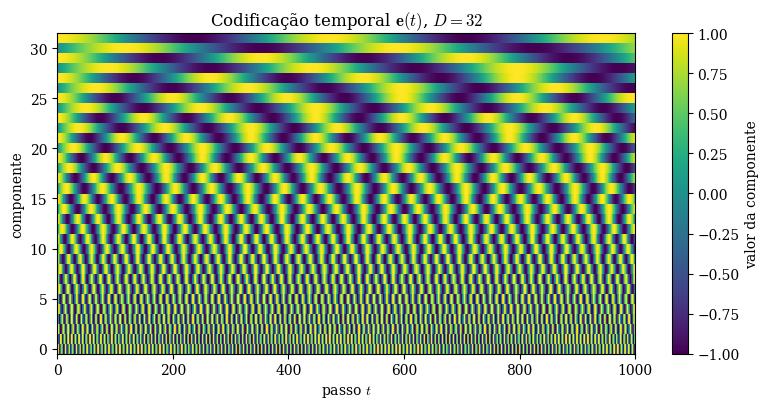

In [ ]:
time_enc = TimeEncoding(T=NUM_STEPS, embed_size=EMBEDDING_SIZE).to(DEVICE)      # Tabela E, (T+1, D)
plot_time_encoding(time_enc)                                                    # Tabela E

In [ ]:
time_steps = torch.tensor([0, NUM_STEPS // 2, NUM_STEPS], dtype=torch.int64)    # define alguns passos de tempo de exemplo: início, meio e fim
emb = time_enc(time_steps).cpu().numpy()                                        # obtém os embeddings correspondentes e converte para NumPy
print(f'emb shape = {emb.shape}')                                               # exibe o formato do resultado (3, EMBEDDING_SIZE)

emb shape = (3, 32)


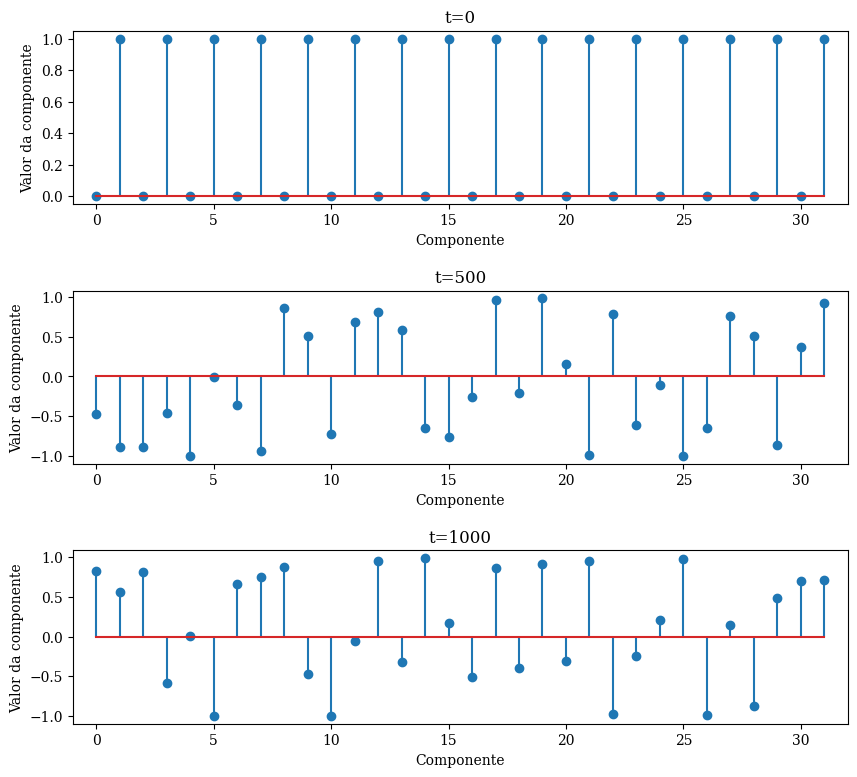

In [ ]:
plt.figure(figsize=(10,9))                                                      # cria figura com tamanho 10x9 polegadas

plt.subplot(3,1,1)                                                              # primeiro subplot (linha 1 de 3)
plt.stem(emb[0])                                                                # plota o embedding do tempo t[0] em formato stem (linha vertical)
plt.title(fr"t={time_steps[0]}")                                                # título com o valor de t
plt.xlabel("Componente")                                                        # rótulo do eixo x: índice da dimensão (0, 1, 2, ..., D−1)
plt.ylabel("Valor da componente")                                               # rótulo do eixo y: valor numérico do embedding (entre -1 e 1)
plt.xlim(-1, EMBEDDING_SIZE)                                                    # limita eixo x ao intervalo [-1, EMBEDDING_SIZE]

plt.subplot(3,1,2)                                                              # segundo subplot (linha 2 de 3)
plt.stem(emb[1])                                                                # plota o embedding do tempo t[1]
plt.title(fr"t={time_steps[1]}")                                                # título com o valor de t
plt.xlabel("Componente")                                                        # rótulo do eixo x: índice da dimensão (0, 1, 2, ..., D−1)
plt.ylabel("Valor da componente")                                               # rótulo do eixo y: valor numérico do embedding (entre -1 e 1)
plt.xlim(-1, EMBEDDING_SIZE)                                                    # define limites do eixo x

plt.subplot(3,1,3)                                                              # terceiro subplot (linha 3 de 3)
plt.stem(emb[2])                                                                # plota o embedding do tempo t[2]
plt.title(fr"t={time_steps[2]}")                                                # título com o valor de t
plt.xlabel("Componente")                                                        # rótulo do eixo x: índice da dimensão (0, 1, 2, ..., D−1)
plt.ylabel("Valor da componente")                                               # rótulo do eixo y: valor numérico do embedding (entre -1 e 1)
plt.xlim(-1, EMBEDDING_SIZE)                                                    # define limites do eixo x

plt.subplots_adjust(hspace=0.5)                                                 # aumenta o espaço vertical entre os subplots

plt.show()                                                                      # exibe todos os subplots

#### Rede preditora de ruído

A rede $\boldsymbol{\epsilon}_\theta$ é uma MLP: a codificação $\mathbf{e}(t)$ passa por uma MLP própria, cuja saída é concatenada a $\mathbf{x}_t$ e processada pela MLP principal, que devolve o ruído predito.

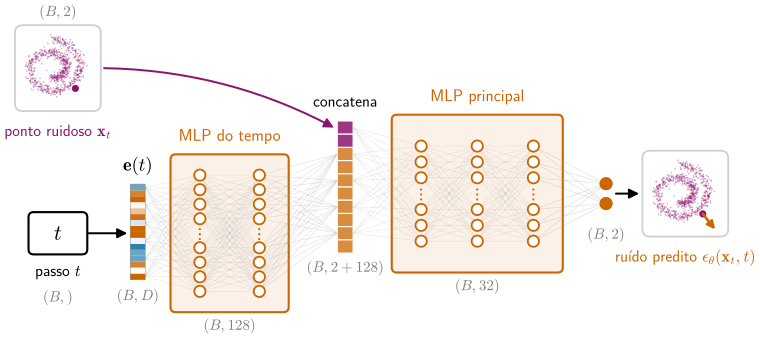

In [ ]:
show_figure("rede_ruido")                                                       # Arquitetura da rede

Utilizaremos a ativação [SiLU](https://docs.pytorch.org/docs/2.15/generated/torch.nn.SiLU.html) [*Sigmoid Linear Unit*], $\mathrm{SiLU}(x) = x\,\sigma(x)$, sendo $\sigma$ a sigmoide: uma versão suave da ReLU.

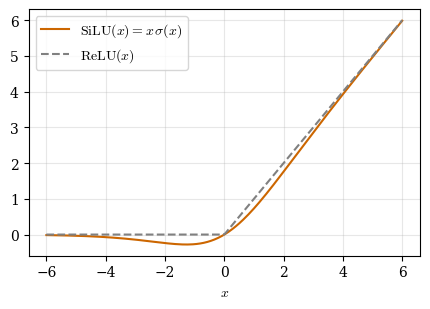

In [ ]:
plot_activation()                                                               # SiLU e ReLU

In [ ]:
class NeuralNet(nn.Module):
    """MLP que prediz o ruído epsilon_theta(x_t, t) a partir de x_t e de t."""

    def __init__(self, time_encoder, hidden_layer_sizes=(32, 32, 32), t_hidden=128):
        super().__init__()
        self.time_encoder = time_encoder                                        # t -> e(t)
        D = time_encoder.embed_size                                             # Dimensão da codificação
        h1, h2, h3 = hidden_layer_sizes                                         # Camadas ocultas
        self.time_mlp = nn.Sequential(                                          # e(t) -> características de t
            nn.Linear(D, t_hidden),                                             # (B, D) -> (B, 128)
            nn.SiLU(),                                                          # Ativação SiLU
            nn.Linear(t_hidden, t_hidden),                                      # (B, 128) -> (B, 128)
        )
        self.main_mlp = nn.Sequential(                                          # [x_t; características] -> ruído
            nn.Linear(2 + t_hidden, h1),                                        # (B, 2 + 128) -> (B, 32)
            nn.SiLU(),                                                          # Ativação SiLU
            nn.Linear(h1, h2),                                                  # (B, 32) -> (B, 32)
            nn.SiLU(),                                                          # Ativação SiLU
            nn.Linear(h2, h3),                                                  # (B, 32) -> (B, 32)
            nn.SiLU(),                                                          # Ativação SiLU
            nn.Linear(h3, 2),                                                   # (B, 32) -> (B, 2): ε_θ(x_t, t)
        )

    def forward(self, x, t):
        """Prediz o ruído contido em x_t: ((B, 2), (B,)) -> (B, 2)."""
        t_emb = self.time_encoder(t)                                            # (B,) -> (B, D)
        t_feat = self.time_mlp(t_emb)                                           # (B, D) -> (B, 128)
        h = torch.cat([x, t_feat], dim=1)                                       # (B, 2 + 128)
        return self.main_mlp(h)                                                 # (B, 2)

### Treinamento

A rede é treinada para predizer o ruído usado no kernel de difusão:

$$\hat{\mathcal{L}}(\theta) = \big\| \underbrace{{\color{red}{\boldsymbol{\epsilon}}}}_{\text{alvo: ruído sorteado}} - \underbrace{\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)}_{\text{predição da rede}} \big\|^2, \qquad \mathbf{x}_t = \sqrt{\bar{\alpha}_t}\,\mathbf{x}_0 + \sqrt{1 - \bar{\alpha}_t}\,\boldsymbol{\epsilon}.$$

A cada mini-lote:

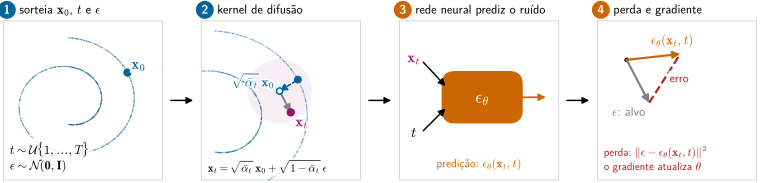

In [ ]:
show_figure("treinamento_difusao")                                              # Um passo de treinamento

1. sorteie, para cada ponto $\mathbf{x}_0$ do lote, um passo $t \sim \mathcal{U}\{1, \ldots, T\}$ e um ruído $\boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$;
2. calcule $\mathbf{x}_t$ pelo kernel de difusão;
3. calcule a predição $\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)$;
4. calcule a perda: o erro quadrático médio entre $\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)$ e $\boldsymbol{\epsilon}$;
5. atualize $\theta$ utilizando gradiente da perda.

### Geração

A geração é uma amostragem ancestral, que aplica o passo reverso $T$ vezes:

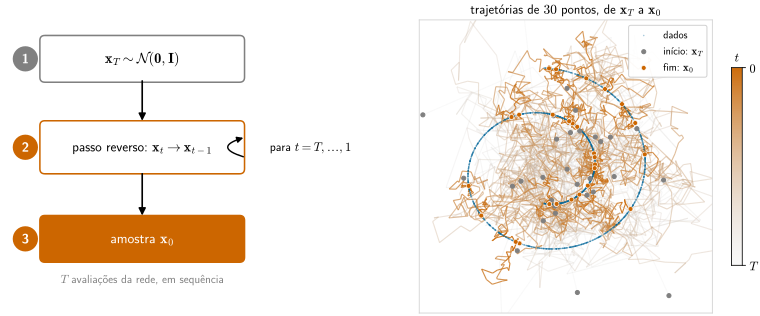

In [ ]:
show_figure("amostragem_difusao")                                               # Amostragem ancestral

1. sorteie $\mathbf{x}_T \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$;
2. para $t = T, T - 1, \ldots, 1$, aplique o passo reverso, $\mathbf{x}_t \to \mathbf{x}_{t-1}$;
3. devolva $\mathbf{x}_0$.

Cada amostra custa $T$ avaliações da rede, em sequência.

### Modelo

`DiffusionModel` reúne a rede e o cronograma:

| Atributo | Nomenclatura | Descrição |
|---|---|---|
| `network` | $\boldsymbol{\epsilon}_\theta$ | rede preditora de ruído |
| `noise_scheduler` | — | cronograma de ruído e kernel de difusão |

Argumentos dos métodos:

| Argumento | Nomenclatura | Descrição |
|---|---|---|
| `x0` | $\mathbf{x}_0$ | lote de dados, shape `(B, 2)` |
| `xt` | $\mathbf{x}_t$ | lote ruidoso no passo $t$, shape `(B, 2)` |
| `t` | $t$ | passo; em `reverse_diffusion_step`, um inteiro comum ao lote |

**Métodos:**

- `compute_loss(x0)` $\to$ perda, um número real (escalar): os passos 1 a 3 do treinamento e o erro quadrático médio entre $\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)$ e $\boldsymbol{\epsilon}$ (`F.mse_loss`);
- `reverse_diffusion_step(xt, t)` $\to$ $\mathbf{x}_{t-1}$, shape `(B, 2)`: os passos 1 a 3 do passo reverso.

<details><summary><b>Detalhes:</b> método <code>reverse_diffusion_step_loop</code></summary>

- `reverse_diffusion_step_loop(batch_size, times_to_show=())` $\to$ `(x0, snaps)`: parte de $\mathbf{x}_T \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$ e aplica `reverse_diffusion_step` para $t = T, \ldots, 1$; `snaps` guarda, na CPU, os $\mathbf{x}_t$ dos passos em `times_to_show`, usados pelas funções de visualização.

</details>

In [ ]:
class DiffusionModel(nn.Module):
    """Rede preditora de ruído e cronograma: perda, passo reverso e geração."""

    def __init__(self, network, noise_scheduler):
        super().__init__()
        self.network = network                                                  # ε_θ(x_t, t)
        self.noise_scheduler = noise_scheduler                                  # β_t, α_t, ᾱ_t e kernel

    def compute_loss(self, x0):
        """Perda de predição do ruído para um lote x_0: (B, 2) -> escalar."""
        T = self.noise_scheduler.T                                              # Número de passos
        t = torch.randint(1, T + 1, (x0.shape[0],), device=x0.device)           # Passo 1: um t por ponto
        noise = torch.randn_like(x0)                                            # Passo 1: ε ~ N(0, I), (B, 2)
        x_noisy = self.noise_scheduler.forward_diffusion(x0, t, noise)          # Passo 2: kernel de difusão
        eps_hat = self.network(x_noisy, t)                                      # Passo 3: ε_θ(x_t, t)
        return F.mse_loss(eps_hat, noise)                                       # Erro quadrático médio

    @torch.no_grad()
    def reverse_diffusion_step(self, xt, t):
        """Amostra x_(t-1) ~ p_theta(x_(t-1) | x_t), com t inteiro comum ao lote."""
        ns = self.noise_scheduler                                               # Atalho para o cronograma
        t_batch = torch.full((xt.shape[0],), t, dtype=torch.long,               # Mesmo t para o lote, (B,)
                             device=xt.device)
        epsilon_pred = self.network(xt, t_batch)                                # Passo 1: ε_θ(x_t, t)
        coef = ns.betas[t] / (1 - ns.alphas_bar[t]).sqrt()                      # β_t / √(1 - ᾱ_t)
        mean = (xt - coef * epsilon_pred) / ns.alphas[t].sqrt()                 # Passo 2: μ_θ(x_t, t)
        z = torch.randn_like(xt) if t > 1 else torch.zeros_like(xt)             # Passo 3: z = 0 se t = 1
        return mean + ns.betas[t].sqrt() * z                                    # x_(t-1) = μ_θ + σ_t·z

    @torch.no_grad()
    def reverse_diffusion_step_loop(self, batch_size=1024, times_to_show=()):
        """Gera pontos a partir de x_T ~ N(0, I); devolve x_0 e os quadros pedidos."""
        self.network.eval()                                                     # Modo de avaliação
        T = self.noise_scheduler.T                                              # Número de passos
        device = self.noise_scheduler.betas.device                              # Dispositivo do modelo
        x_pred = torch.randn((batch_size, 2), device=device)                    # x_T ~ N(0, I)
        snaps = {T: x_pred.cpu()} if T in times_to_show else {}                 # Guarda x_T, se pedido
        for t in tqdm(range(T, 0, -1), desc="Amostragem (processo reverso)",    # t = T, ..., 1
                      unit="passo", leave=False):
            x_pred = self.reverse_diffusion_step(x_pred, t)                     # x_t -> x_(t-1)
            if t - 1 in times_to_show:                                          # Passo pedido
                snaps[t - 1] = x_pred.cpu()                                     # Guarda x_(t-1) na CPU
        return x_pred, snaps

`build_diffusion_model` instancia as quatro partes com o mesmo $T$:

In [ ]:
def build_diffusion_model(num_steps=NUM_STEPS, embedding_size=EMBEDDING_SIZE, mode=MODE):
    """Instancia cronograma, codificação temporal, rede e modelo com o mesmo T."""
    noise_scheduler = NoiseScheduler(T=num_steps, mode=mode)                    # β_t, α_t, ᾱ_t
    time_enc = TimeEncoding(T=num_steps, embed_size=embedding_size)             # Tabela E, (T+1, D)
    network = NeuralNet(time_encoder=time_enc)                                  # ε_θ(x_t, t)
    return DiffusionModel(network, noise_scheduler).to(DEVICE)                  # Modelo no dispositivo

### Laço de treinamento

A cada época, `train_one_epoch` percorre os mini-lotes, chama `model.compute_loss` e atualiza $\theta$ com o otimizador. `train_diffusion_model` repete isso por `num_epochs` épocas e devolve um `TrainingHistory`:

| Campo | Descrição |
|---|---|
| `loss` | perda média de cada época |
| `train_time` | duração do treinamento, em segundos |

In [ ]:
class TrainingHistory(NamedTuple):
    """Perda média de cada época e duração do treinamento."""
    loss: list                                                                  # Perda média por época
    train_time: float                                                           # Duração, em segundos


def train_one_epoch(model, dataloader, optimizer):
    """Executa uma época de treinamento e devolve a perda média por amostra."""
    model.train()                                                               # Modo de treinamento
    total_loss = 0.0                                                            # Soma das perdas da época
    for (xb,) in dataloader:
        xb = xb.to(DEVICE)                                                      # Lote x_0, (B, 2)
        optimizer.zero_grad()                                                   # Zera os gradientes
        loss = model.compute_loss(xb)                                           # Passos 1 a 3 e a perda
        loss.backward()                                                         # Retropropagação
        optimizer.step()                                                        # Passo 4: atualiza θ
        total_loss += loss.item() * xb.shape[0]                                 # Soma ponderada pelo lote
    return total_loss / len(dataloader.dataset)                                 # Perda média da época


def train_diffusion_model(model, dataloader, num_epochs, optimizer, tag):
    """Treina o modelo por num_epochs épocas e devolve o histórico de treinamento."""
    losses = []                                                                 # Perda média de cada época
    start = time.perf_counter()                                                 # Início do treinamento
    pbar = tqdm(range(num_epochs), desc=f"[{tag}] Épocas", unit="época")        # Barra de progresso
    for _ in pbar:
        losses.append(train_one_epoch(model, dataloader, optimizer))            # Uma época
        pbar.set_postfix({"Perda": f"{losses[-1]:.5f}"})                        # Mostra a perda atual
    return TrainingHistory(losses, time.perf_counter() - start)

## Experimento

### Treinamento na configuração base

Treina um modelo com os hiperparâmetros da seção Hiperparâmetros, no conjunto `DATASET`:

In [ ]:
torch.manual_seed(SEED)                                                         # Fixa a inicialização dos pesos
model = build_diffusion_model()                                                 # Configuração base
summary(model.network,                                                          # Resumo da rede
        input_size=[(1, 2), (1,)],                                              # Entradas: x_t (B, 2) e t (B,)
        dtypes=[torch.float32, torch.long],                                     # Real para x_t, inteiro para t
        col_names=["input_size", "output_size", "num_params"])                  # Colunas exibidas

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
NeuralNet                                [1, 2]                    [1, 2]                    --
├─TimeEncoding: 1-1                      [1]                       [1, 32]                   --
├─Sequential: 1-2                        [1, 32]                   [1, 128]                  --
│    └─Linear: 2-1                       [1, 32]                   [1, 128]                  4,224
│    └─SiLU: 2-2                         [1, 128]                  [1, 128]                  --
│    └─Linear: 2-3                       [1, 128]                  [1, 128]                  16,512
├─Sequential: 1-3                        [1, 130]                  [1, 2]                    --
│    └─Linear: 2-4                       [1, 130]                  [1, 32]                   4,192
│    └─SiLU: 2-5                         [1, 32]                   [1, 32]                   --
│    └─Linear: 2-6       

[BASE] Épocas:   0%|          | 0/50 [00:00<?, ?época/s]

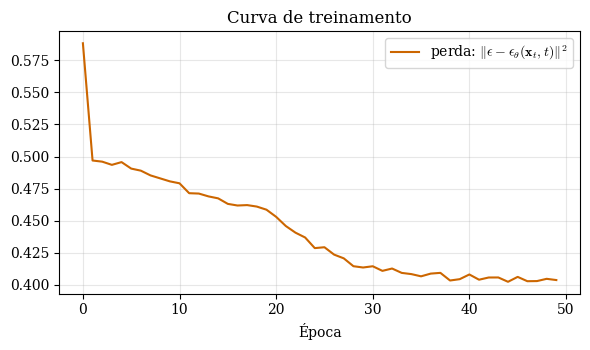

In [ ]:
optimizer = optim.Adam(model.network.parameters(), lr=LEARNING_RATE)            # Adam sobre os pesos da rede
history = train_diffusion_model(model, train_dl, NUM_EPOCHS, optimizer,         # Perda por época
                                tag="BASE")
plot_training_curve(history)                                                    # Curva de perda

### Visualização

Funções do `diffusion_utils.py`:

| Função | Descrição |
|---|---|
| `show_figure` | figura do laboratório (SVG), baixada do Drive se preciso |
| `plot_data` | dados sobre amostras de $\mathcal{N}(\mathbf{0}, \mathbf{I})$ |
| `show_animation` | animação salva em HTML, baixada do Drive se preciso |
| `plot_noise_schedule` | coeficientes de cada passo, nível do sinal e nível do ruído, em três painéis |
| `_frame` | quadro de pontos 2D com janela fixa, usado por `plot_forward_process` e `plot_reverse_process` |
| `plot_time_encoding` | mapa de calor da tabela $\mathbf{E}$ da codificação temporal |
| `plot_activation` | SiLU e ReLU |
| `plot_training_curve` | perda por época |
| `compare_training_curves` | curvas de perda de várias execuções, sobrepostas |
| `compare_processes` | processos direto e reverso nos mesmos passos |
| `plot_trajectories` | trajetórias de pontos no processo reverso |
| `animate_reverse_process` | animação do processo reverso |
| `load_datasaurus` | um conjunto do Datasaurus, padronizado, para a tarefa |
| `plot_datasaurus` | os $13$ conjuntos do Datasaurus, padronizados, para a tarefa |

As funções que geram amostras fixam a semente (`seed=42`): modelos diferentes partem dos mesmos $\mathbf{x}_T$.

#### Geração

In [ ]:
def plot_samples(model, num_samples=1024, seed=42):
    """Plota amostras 2D geradas pelo modelo. """
    torch.manual_seed(seed)
    samples, _ = model.reverse_diffusion_step_loop(num_samples)
    samples = samples.detach().cpu().numpy()

    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(samples[:, 0],
               samples[:, 1],
               s=9,
               color="tab:blue",
               alpha=0.75,
               linewidths=0)
    ax.set_aspect("equal", adjustable="box")
    ax.margins(0.06)
    ax.set_title("Amostras geradas")
    plt.tight_layout()
    plt.show()

Amostragem (processo reverso):   0%|          | 0/1000 [00:00<?, ?passo/s]

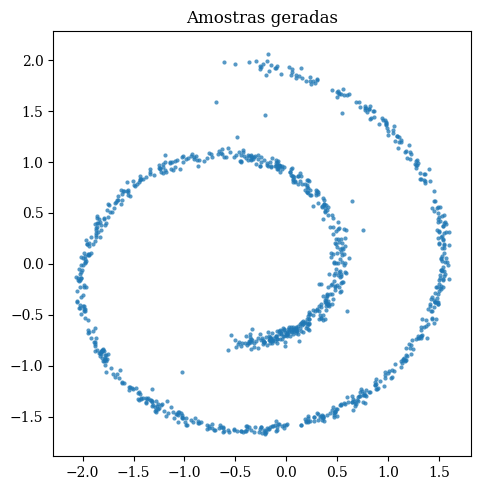

In [ ]:
plot_samples(model)                                                             # Amostras geradas

#### Processo de difusão reverso

In [ ]:
ORANGE = "#CC6600"

def plot_reverse_process(model, num_points=1000, num_frames=11, seed=42, title=None, color=ORANGE):
    """Quadros de p_theta(x_t) em passos igualmente espaçados, de t = T a t = 0."""
    T = model.noise_scheduler.T                                                 # Número de passos
    times = (np.unique(np.linspace(0, T, num_frames)                            # Passos exibidos: T, ..., 0
            .round()
            .astype(int)
            )[::-1])
    torch.manual_seed(seed)                                                     # Fixa x_T e os z
    _, snaps = model.reverse_diffusion_step_loop(                               # x_t dos passos exibidos
        num_points, times_to_show=set(times.tolist()))
    fig, axs = plt.subplots(1, len(times),                                      # Um quadro por passo
                            figsize=(1.75 * len(times), 2.3))
    for ax, t in zip(axs, times):
        label = rf"$p_\theta(\mathbf{{x}}_{{{t}}})$"                            # Título do quadro
        _frame(ax, snaps[int(t)], color, label)                                 # Quadro do passo t
    if title:
        fig.suptitle(title)                                                     # Identifica a execução
    plt.tight_layout()                                                          # Ajusta as margens
    plt.show()

Amostragem (processo reverso):   0%|          | 0/1000 [00:00<?, ?passo/s]

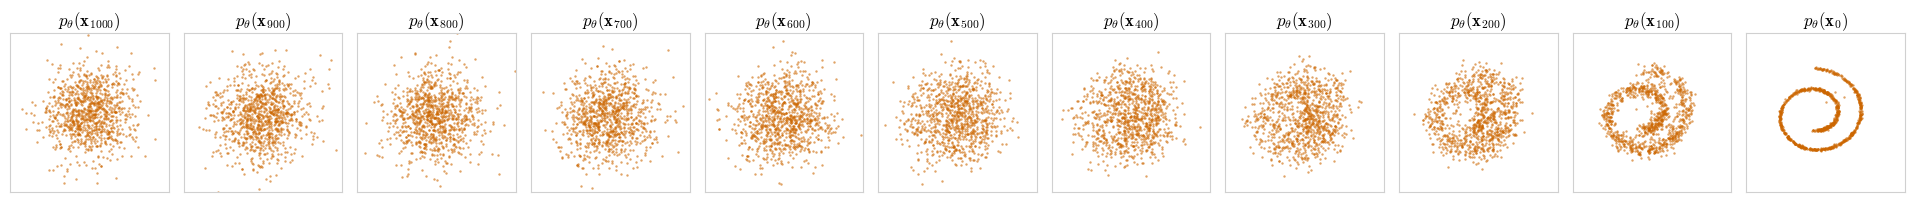

In [ ]:
plot_reverse_process(model)                                                     # p_θ(x_t), de T a 0

#### Processos de difusão direto e reverso

Amostragem (processo reverso):   0%|          | 0/1000 [00:00<?, ?passo/s]

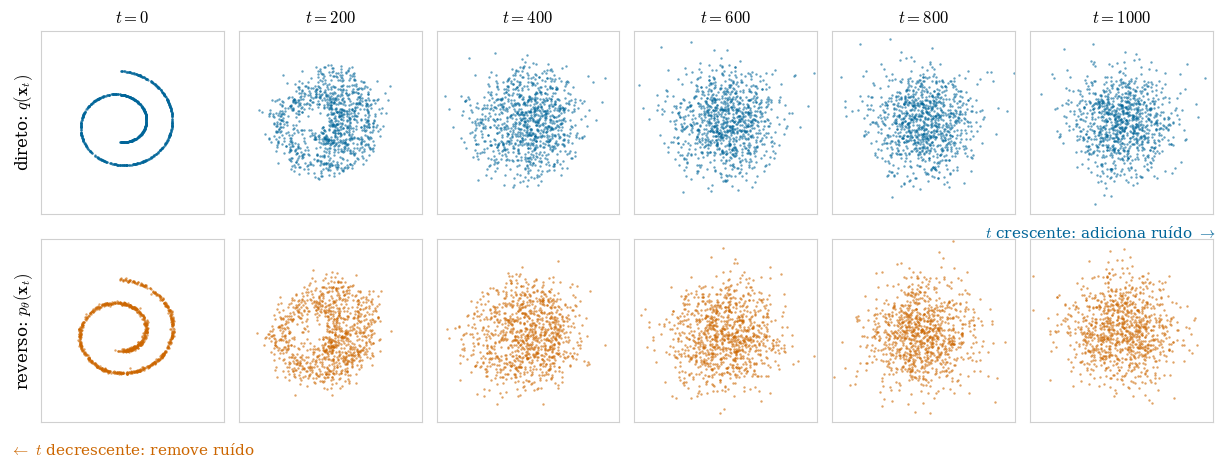

In [ ]:
compare_processes(model, X)                                                     # q e p_θ nos mesmos passos

A trajetória de um ponto é a sequência $\mathbf{x}_T, \mathbf{x}_{T-1}, \ldots, \mathbf{x}_0$ que ele percorre no processo reverso:

Amostragem (processo reverso):   0%|          | 0/1000 [00:00<?, ?passo/s]

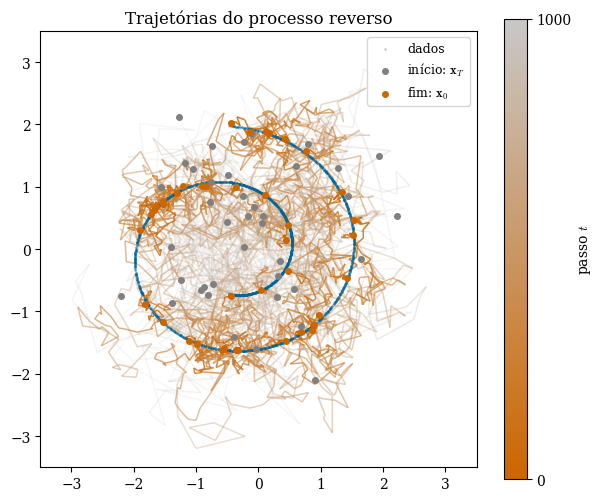

In [ ]:
plot_trajectories(model, X)                                                     # Caminhos de 40 pontos

In [ ]:
animate_reverse_process(model)                                                  # Animação de p_θ(x_t)

Amostragem (processo reverso):   0%|          | 0/1000 [00:00<?, ?passo/s]

# Tarefa (em duplas)

**Treinar o modelo de difusão com um conjunto do Datasaurus, à escolha da dupla, e investigar o efeito do número de passos de difusão $T$ e da dimensão $D$ da codificação temporal no processo reverso e nas amostras geradas**

Cada item tem uma seção **Resposta**, com uma célula de código. Você pode acrescentar células, mas não apague nem reordene os enunciados.

**Baseline:**

| Parâmetro | Valor |
|---|---|
| Conjunto de dados | um conjunto do Datasaurus, com `NUM_SAMPLES` pontos |
| Número de passos | $T = 1000$ |
| Dimensão da codificação temporal | $D = 32$ |
| Cronograma de ruído | cosseno |
| Épocas | `NUM_EPOCHS` ou mais, o mesmo número em todas as execuções |
| Tamanho do lote | $256$ |
| Otimizador | Adam, com taxa de aprendizado $10^{-3}$ |
| Pontos gerados na amostragem | `BATCH_SIZE_SAMPLING` |
| Semente | `SEED`, antes de instanciar cada modelo |

Os valores do baseline são os da seção Hiperparâmetros, exceto o conjunto de dados e, se for preciso, o número de épocas. Cada execução usa um modelo novo, de `build_diffusion_model`, e um otimizador novo.

> **Atenção:** os conjuntos do Datasaurus têm detalhes mais finos que o *swiss roll*, e as $50$ épocas de `NUM_EPOCHS` podem não bastar. Pode ser necessário treinar por $300$ épocas ou mais.

**Mostrar:**

- figuras: em cada item, as curvas de perda de todas as execuções sobrepostas, com legenda (`compare_training_curves`), e, para cada execução, as amostras geradas (`plot_samples`) e o processo reverso (`plot_reverse_process`);
- tabela: para cada execução a perda da última época.

**Entregáveis:**

Ao final da Unidade 2, você entregará **o notebook de cada laboratório da unidade**,
um arquivo `.ipynb` por laboratório, com a tarefa respondida ao final.

Cada notebook deve **executar do início ao fim sem erros**, em um kernel novo,
com *Restart & Run All*. Antes de entregar, execute-o dessa forma e confirme
que todas as células rodam na ordem em que aparecem e que as saídas exibidas
correspondem a essa execução. Notebooks que não executarem por completo serão
penalizados.

A entrega é **única por grupo**. Identifique os integrantes no início de cada
notebook.

## 0. Configuração base

**Experimento:** escolha um dos [conjuntos do Datasaurus](https://github.com/jumpingrivers/datasauRus/tree/main) ([Matejka and Fitzmaurice, 2017](https://doi.org/10.1145/3025453.3025912)), mostrados na célula abaixo, carregue-o em `X` com `load_datasaurus`, recrie `train_dl` e treine um modelo na configuração base. Mostre as figuras da seção Visualização dessa execução.

A função `load_datasaurus(num_samples, dataset)`, do `diffusion_utils.py`, baixa o arquivo `DatasaurusDozen-Long.tsv`, se preciso, e devolve o conjunto pedido. Cada conjunto tem só $142$ pontos: a função padroniza as coordenadas, como `load_datasets_2d`, e sorteia os pontos com reposição até completar `num_samples`. Por exemplo, para o conjunto `"dino"`:

```python
X = load_datasaurus(NUM_SAMPLES, "dino")                                        # x_0, shape (NUM_SAMPLES, 2)
train_ds = TensorDataset(X)                                                     # Conjunto de tensores
train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)            # Mini-lotes embaralhados
plot_data(X)                                                                    # Dados sobre N(0, I)
```

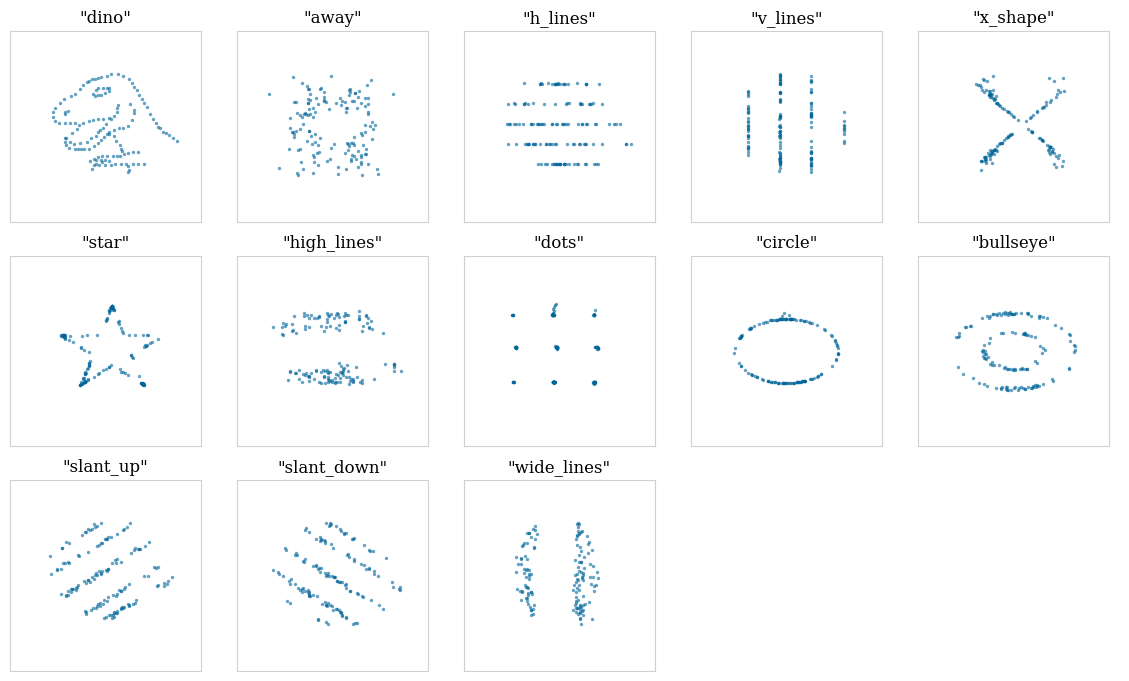

In [ ]:
plot_datasaurus()                                                               # Os 13 conjuntos do Datasaurus

### Resposta

## 1. Efeito do número de passos $T$

**Experimento:** treine o modelo para $T \in \{10, 100, 1000\}$, com um modelo novo para cada valor, fixando:

- $D = 32$;
- os demais parâmetros do baseline.

A execução com $T = 1000$ é a configuração base: reaproveite o modelo do item 0. Mostre também os processos direto e reverso de cada valor de $T$ (`plot_forward_process` , `plot_reverse_process`).

### Resposta

## 2. Efeito da dimensão $D$ da codificação temporal

**Experimento:** treine o modelo para $D \in \{2, 8, 32\}$, com um modelo novo para cada valor, fixando:

- $T = 1000$;
- os demais parâmetros do baseline.

A execução com $D = 32$ é a configuração base: reaproveite o modelo do item 0.
Mostre também os processos direto e reverso de cada valor de $D$ (`plot_forward_process` , `plot_reverse_process`).

### Resposta

## 3. Geração

**Experimento:** Mostre em uma grade $3 \times 3$ os dados gerados para cada combinação $T$ e $D$, onde as linhas representam os valoes de $T$ e as colunas os valores de $D$. Comente os resultados obtidos.

### Resposta